In [1]:
import os
import tensorflow as tf

print(os.listdir("../data/raw"))
print(tf.__version__)

['Intel_Image_Classification']
2.22.0-rc0


In [2]:
# Split the labeled images into train, validation, and test (70/15/15)
import random
from pathlib import Path

train_dir = Path(
    "../data/raw/Intel_Image_Classification/seg_train_test/seg_train"
)
class_names = sorted(
    folder.name for folder in train_dir.iterdir() if folder.is_dir()
)

# seg_pred is unlabeled, so split the labeled seg_train images instead.
random_generator = random.Random(42)
splits = {
    "train": ([], []),
    "validation": ([], []),
    "test": ([], []),
}

# Split each class separately so all sets contain every class.
for label_number, class_name in enumerate(class_names):
    class_dir = train_dir / class_name
    image_paths = [
        path
        for path in class_dir.iterdir()
        if path.is_file()
        and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]
    random_generator.shuffle(image_paths)

    train_end = int(len(image_paths) * 0.70)
    validation_end = int(len(image_paths) * 0.85)
    class_splits = {
        "train": image_paths[:train_end],
        "validation": image_paths[train_end:validation_end],
        "test": image_paths[validation_end:],
    }

    for split_name, paths in class_splits.items():
        splits[split_name][0].extend(str(path) for path in paths)
        splits[split_name][1].extend([label_number] * len(paths))

    print(
        f"{class_name}: "
        f"train={len(class_splits['train'])}, "
        f"validation={len(class_splits['validation'])}, "
        f"test={len(class_splits['test'])}"
    )

def load_image(file_path, label):
    image_bytes = tf.io.read_file(file_path)
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (150, 150))
    return image, label

def make_dataset(paths, labels, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        dataset = dataset.shuffle(len(paths), seed=42)
    dataset = dataset.map(
        load_image, num_parallel_calls=tf.data.AUTOTUNE
    )
    return dataset.batch(32).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(*splits["train"], shuffle=True)
val_ds = make_dataset(*splits["validation"])
test_ds = make_dataset(*splits["test"])

print("Categories:", class_names)
print("Train images:", len(splits["train"][0]))
print("Validation images:", len(splits["validation"][0]))
print("Test images:", len(splits["test"][0]))

buildings: train=1839, validation=394, test=395


forest: train=1921, validation=412, test=412


glacier: train=2069, validation=444, test=444


mountain: train=2125, validation=456, test=456


sea: train=1948, validation=418, test=418


street: train=2018, validation=432, test=433


Categories: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Train images: 11920
Validation images: 2556
Test images: 2558


In [3]:
images, labels = next(iter(train_ds))

print("Shape:", images.shape)
print("labels:", labels.shape)

label_number = int(labels[0].numpy())
print("Label_number:",label_number)
print("Class name:", class_names[label_number])

Shape: (32, 150, 150, 3)
labels: (32,)
Label_number: 1
Class name: forest


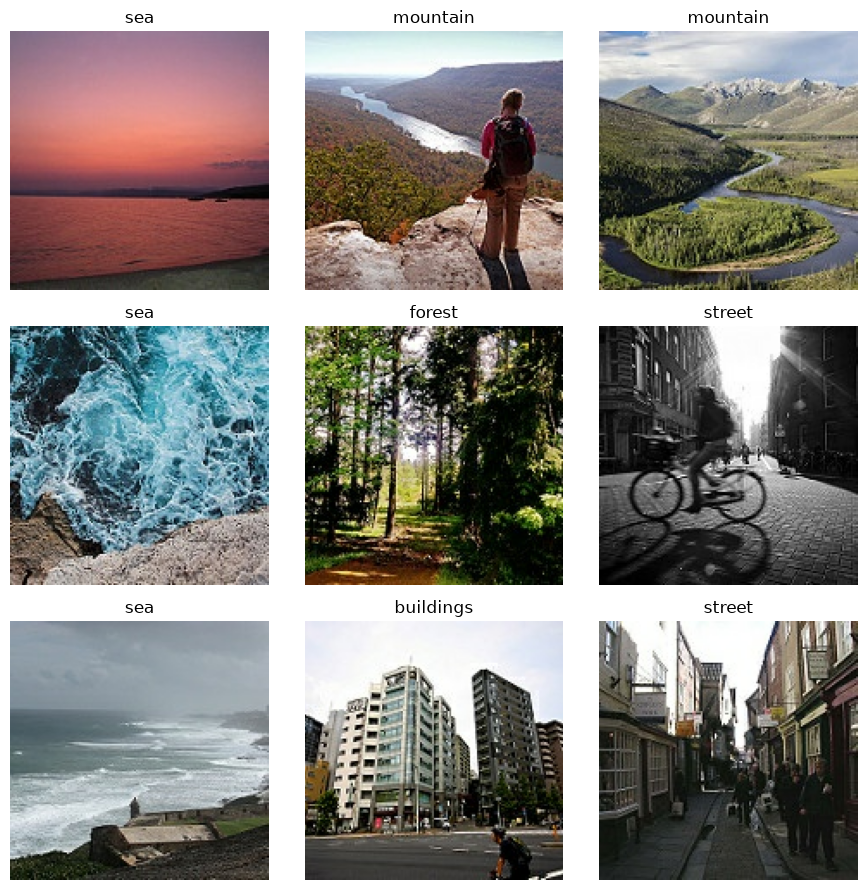

In [4]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_ds))

plt.figure(figsize=(9, 9))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))

    label_number = int(labels[i].numpy())
    plt.title(class_names[label_number])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
from PIL import Image
from pathlib import Path
image_path = next(Path(train_dir).glob("*/*"))
with Image.open(image_path) as image:
    print("File: ", image_path.name)
    print("Format: ", image.format)
    print("Size: ", image.size)

File:  0.jpg
Format:  JPEG
Size:  (150, 150)


In [6]:
from pathlib import Path

train_path = Path(train_dir)

image_extensions = {".jpg", ".jpeg", ".png"}
total_images = 0

for class_dir in sorted(train_path.iterdir()):
    if class_dir.is_dir():
        image_count = sum(
            1
            for image_path in class_dir.iterdir()
            if image_path.is_file() and image_path.suffix.lower() in image_extensions
        )
        total_images += image_count
        print(f"{class_dir.name}: {image_count} images")

print(f"Total: {total_images} images")

buildings: 2628 images
forest: 2745 images
glacier: 2957 images


mountain: 3037 images


sea: 2784 images
street: 2883 images
Total: 17034 images
